In [55]:
import pandas as pd
import numpy as np
from scipy.stats import skew
from scipy.stats import kurtosis
from scipy.stats import mode

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.fft import fft, fftfreq
from pathlib import Path
import os
import shutil

import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

In [2]:
dataset_path = "./dataset/radar-data-for-machine-fault-detection/dataset"
dataset_data_details = dataset_path + "/Data_Details.csv"

def checarSeExiste(file):
    arquivo = Path(file)
    return arquivo.exists()

def limparPasta(file):
    for arquivo in os.listdir(file):
        caminho = os.path.join(file, arquivo)
        if os.path.isfile(caminho) or os.path.islink(caminho):
            os.remove(caminho)
        elif os.path.isdir(caminho):
            shutil.rmtree(caminho)

def load_dataDetails():
    df_details = pd.read_csv(dataset_data_details, sep=";") # lendo arquivo
    df_details = df_details.iloc[:, :-1] # removendo último coluna

    # Renomeando colunas
    df_details = df_details.rename(columns={
        "Data_name":"dataName",
        "Motor speed (rpm)":"motorSpeed",
        "Load (Nm)":"load",
        "Class":"class"
        })

    # Adicionando caminho dos dados brutos
    df_details["rawData"] = dataset_path + "/raw_data/" + \
        df_details["class"].str.lower().str.split(' ', n=1).str[0] + "/" + \
        df_details["dataName"] + ".csv"


    df_details['motorSpeed'] = pd.to_numeric(df_details["motorSpeed"].str.replace(",", ".", regex=False),  errors="coerce")
    df_details['load'] = pd.to_numeric(df_details["load"].str.replace(",", ".", regex=False),  errors="coerce")

    df_details = df_details.dropna(subset=["motorSpeed"])

    df_details["dataRawExists"] = df_details["rawData"].apply(checarSeExiste)
    df_details = df_details[df_details["dataRawExists"] == True]
    df_details = df_details.drop(columns="dataRawExists")
    df_details.reset_index(drop=True)

    return df_details

def load_rawData(dataFile):
    df_rawData = pd.read_csv(dataFile, sep=",",decimal=".") # lendo arquivo

    df_rawData["module"] = np.sqrt(np.pow(df_rawData["Q_data"],2) + np.pow(df_rawData["I_data"],2)) # Calculando modulo do sinal
    df_rawData["fase"] = np.atan(df_rawData["Q_data"]/df_rawData["I_data"]) # Calculando fase do sinal

    df_rawData = df_rawData[df_rawData["module"] > 0] # Filtrando valores não nulos

    return df_rawData



df_dataDetails = load_dataDetails()
df_dataDetails.info()



<class 'pandas.DataFrame'>
Index: 461 entries, 0 to 461
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dataName    461 non-null    str    
 1   motorSpeed  461 non-null    float64
 2   load        461 non-null    float64
 3   class       461 non-null    str    
 4   rawData     461 non-null    str    
dtypes: float64(2), str(3)
memory usage: 21.6 KB


<h1>Pré-Processamento do Sinal</h1>

<h2>A) Extração de Features</h2>

In [3]:
def extract_time_features(data):
    time_features = {
        "amplitude": np.max(data) - np.min(data),
        "energy": np.sum(data**2),
        "kurtosis": kurtosis(data, fisher=False),
        "max": np.max(data),
        "mean": np.mean(data),
        "median": np.median(data),
        "min": np.min(data),
        "mode": mode(data, keepdims=False).mode,
        "rms": np.sqrt(np.mean(data**2)),
        "skewness": skew(data),
        "std": np.std(data),
        "variance": np.var(data)
    }
    return time_features

def extract_freq_features(data):
    df_rawData = data.copy()
    df_rawData["f(t)"] = data["I_data"] + data["Q_data"]*1j

    fs = 10000 #amostras por segundo 10kHz
    N = df_rawData.shape[0]

    Z = fft(df_rawData["f(t)"])
    freq = fftfreq(N, 1/fs)

    # Apenas frequências positivas
    mask = freq >= 0

    freq = freq[mask]
    magnitude = np.abs(Z)[mask]


    # Frequência dominante
    idx_dominante = np.argmax(magnitude)
    frequencia_dominante = freq[np.argmax(magnitude)]
    magnitude_freq_dominante = magnitude[idx_dominante]

    # Frequência média ponderada pela magnitude
    frequencia_media = np.average(freq, weights=magnitude) 

    # Frequência mediana ponderada
    magnitude_acumulada = np.cumsum(magnitude)
    limite = magnitude_acumulada[-1] / 2

    idx_mediana = np.searchsorted(magnitude_acumulada, limite)
    frequencia_mediana = freq[idx_mediana]

    # Energia espectral
    energia_espectral = np.sum(magnitude ** 2)

    # Largura de banda
    # RMS bandwidth
    frequencia_centroide = frequencia_media
    largura_banda = np.sqrt(
        np.sum(
            magnitude * (freq - frequencia_centroide) ** 2
        ) / np.sum(magnitude)
    )

    # Curtose e assimetria do espectro
    assimetria = skew(magnitude)
    curtose = kurtosis(
        magnitude,
        fisher=False
    )

    return {
        "bandwidth": largura_banda,
        "dominant_frequency": frequencia_dominante,
        "dominant_frequency_magnitude": magnitude_freq_dominante,
        "energy_spectral": energia_espectral,
        "frequency_mean": frequencia_media,
        "frequency_median": frequencia_mediana,
        "kurtosis": curtose,
        "skewness": assimetria
    }


def extract_features(dataDetails):
    dataDetails = dataDetails.copy()
    total = dataDetails.shape[0]
    for indice, data in dataDetails.iterrows():
        data_rawData = load_rawData(dataFile=data["rawData"])

        # features domínio do tempo:
        I_features = extract_time_features(data_rawData["I_data"])
        for feature, value in I_features.items(): dataDetails.loc[indice, "I_" + feature] = value

        Q_features = extract_time_features(data_rawData["Q_data"])
        for feature, value in Q_features.items(): dataDetails.loc[indice, "Q_" + feature] = value

        module_features = extract_time_features(data_rawData["module"])
        for feature, value in module_features.items(): dataDetails.loc[indice, "module_" + feature] = value

        fase_features = extract_time_features(data_rawData["fase"])
        for feature, value in fase_features.items(): dataDetails.loc[indice, "fase_" + feature] = value

        # features domínio da freqência:
        data_fft_features = extract_freq_features(data_rawData)
        for feature, value in data_fft_features.items(): dataDetails.loc[indice, "fft_" + feature] = value

        print(f"\r{((indice) / total) * 100:.2f}% concluído!", end="")
    return dataDetails

print("Iniciando processo de extração....")
df_dataDetails = extract_features(df_dataDetails)


Iniciando processo de extração....
100.00% concluído!

In [4]:
df_dataDetails.describe()

,motorSpeed,load,I_amplitude,I_energy,I_kurtosis,I_max,I_mean,I_median,I_min,I_mode,...,fase_std,fase_variance,fft_bandwidth,fft_dominant_frequency,fft_dominant_frequency_magnitude,fft_energy_spectral,fft_frequency_mean,fft_frequency_median,fft_kurtosis,fft_skewness
count,461.000000,461.000000,461.000000,4.610000e+02,461.000000,461.000000,461.000000,461.000000,461.000000,461.000000,...,461.000000,461.000000,461.000000,461.0,4.610000e+02,4.610000e+02,461.000000,461.000000,461.000000,461.000000
mean,1000.650759,1.247289,5.025818,2.234795e+06,2.764410,5.081205,2.588166,2.562841,0.055387,2.755542,...,0.227278,0.053092,1025.226564,0.0,1.096020e+06,1.254703e+12,734.391420,327.286623,138185.202608,364.775826
std,316.604968,0.853776,0.397606,1.229245e+05,0.353965,0.278402,0.098347,0.120588,0.177410,1.384420,...,0.037941,0.018314,48.067800,0.0,4.169037e+04,5.861902e+10,71.064494,57.882610,3139.419005,5.935495
min,500.000000,0.000000,0.010212,6.968552e+04,2.138645,0.488293,0.481955,0.483187,-0.006993,-0.001887,...,0.003084,0.000010,906.685125,0.0,2.031899e+05,4.128660e+10,533.304438,160.933333,122885.337694,339.222530
25%,700.000000,0.500000,5.070299,2.188089e+06,2.499611,5.088837,2.592230,2.510286,-0.001887,2.321362,...,0.206153,0.042499,1003.214215,0.0,1.097676e+06,1.244446e+12,697.279313,287.933333,136762.203101,362.083086
50%,1000.000000,1.000000,5.182632,2.242607e+06,2.625299,5.180745,2.593176,2.561346,-0.001887,2.535816,...,0.221239,0.048947,1026.956409,0.0,1.098164e+06,1.257589e+12,736.036661,330.233333,138180.665436,364.735441
75%,1300.000000,2.000000,5.192844,2.272557e+06,2.958863,5.190957,2.593913,2.637937,-0.001887,2.949405,...,0.243028,0.059063,1047.134383,0.0,1.098496e+06,1.263996e+12,770.354657,366.900000,141029.017494,370.108967
max,1500.000000,2.500000,5.197950,2.543589e+06,3.748325,5.196064,2.597581,2.694103,0.917201,5.180745,...,0.399050,0.159241,1717.810915,0.0,1.099652e+06,1.335009e+12,1432.567938,517.833333,149997.112676,387.292743


<h2> B) Correlação dos dados - Remoção de Features altamente correlacionadas </h2>

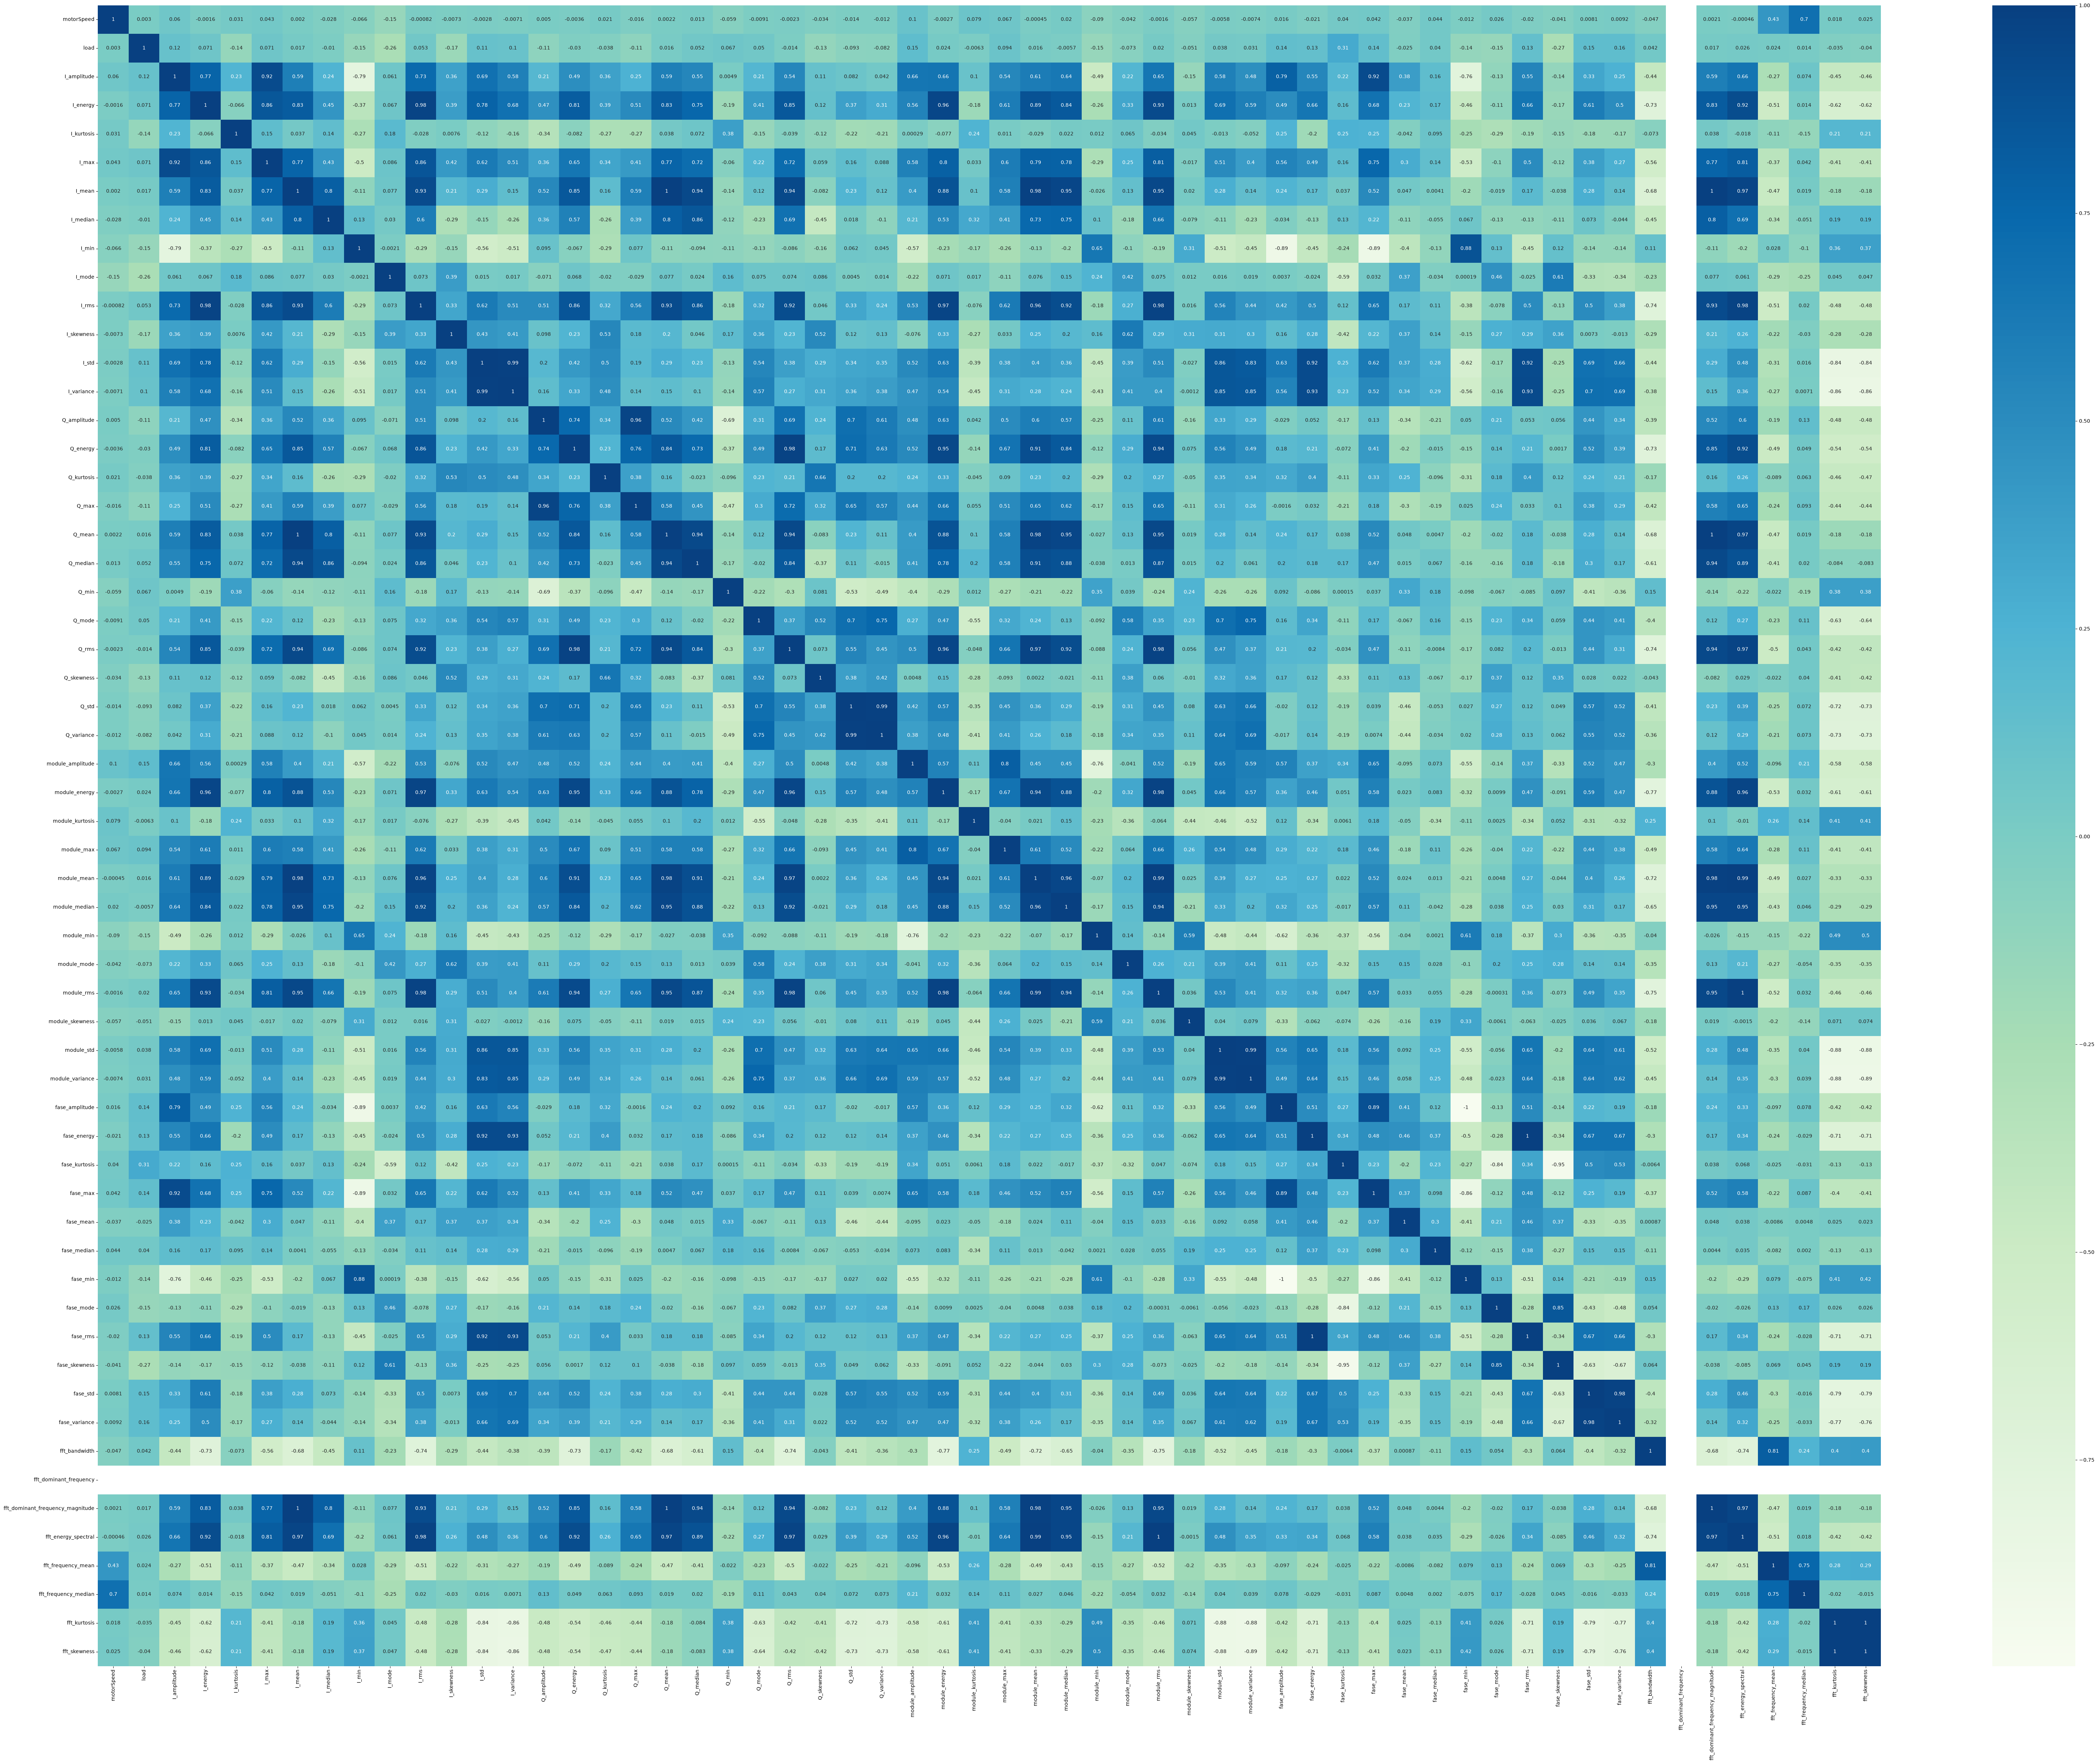

In [ ]:
%matplotlib inline

data_numeric = df_dataDetails.select_dtypes(include="number")

def heatmap_corr(data):
    plt.rcParams['figure.figsize'] = [80, 60]
    sns.heatmap(data.corr(),
                annot=True,
                cmap="GnBu"
    )
heatmap_corr(data_numeric)

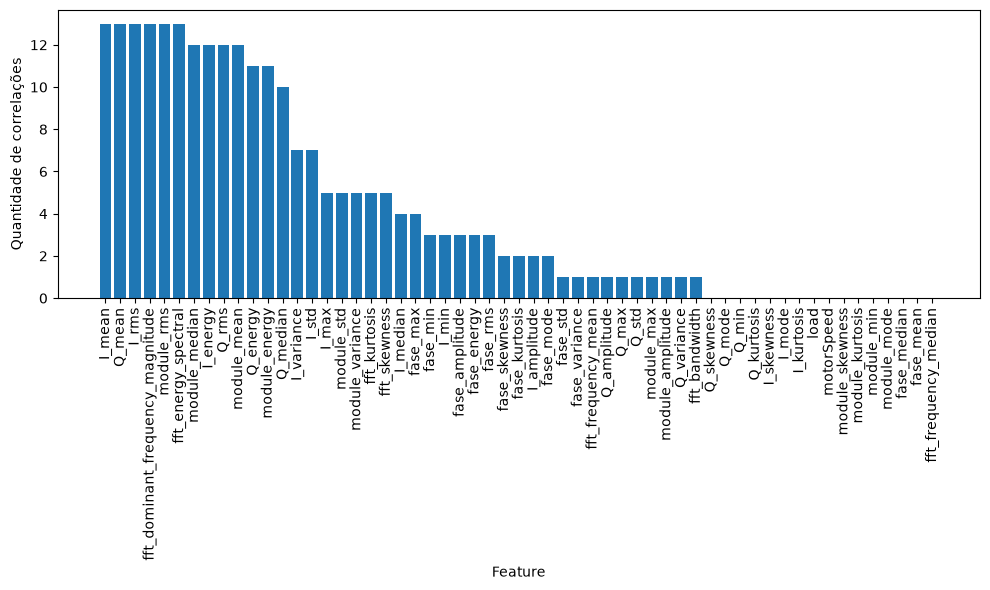

Features removidas:
I_amplitude
I_energy
I_mean
I_median
I_min
I_rms
I_std
I_variance
Q_amplitude
Q_mean
Q_rms
Q_variance
fase_max
fase_min
fase_mode
fase_rms
fase_skewness
fase_std
fft_dominant_frequency
fft_dominant_frequency_magnitude
fft_energy_spectral
fft_frequency_mean
fft_kurtosis
fft_skewness
module_amplitude
module_energy
module_mean
module_median
module_rms
module_variance


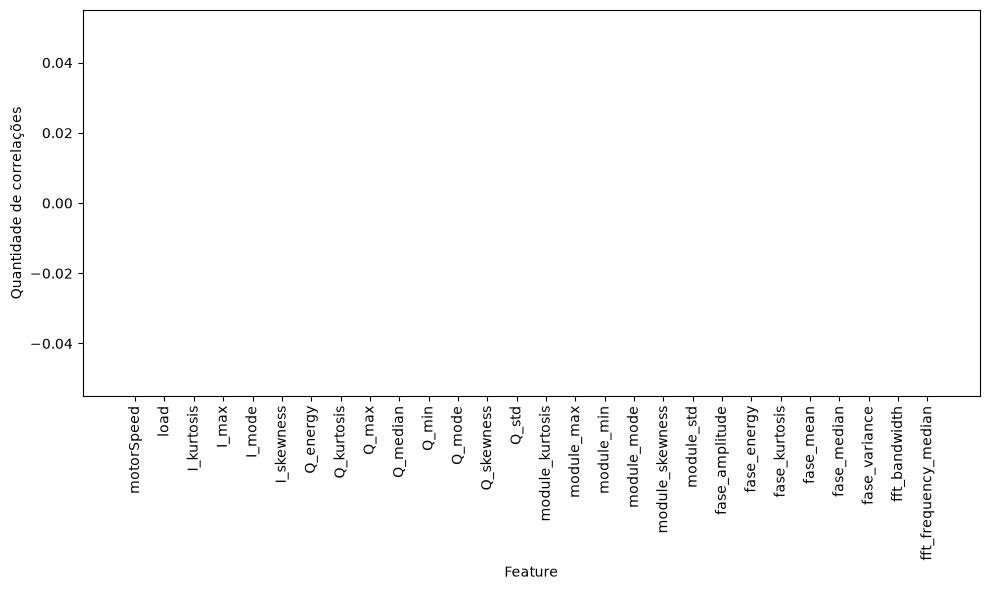

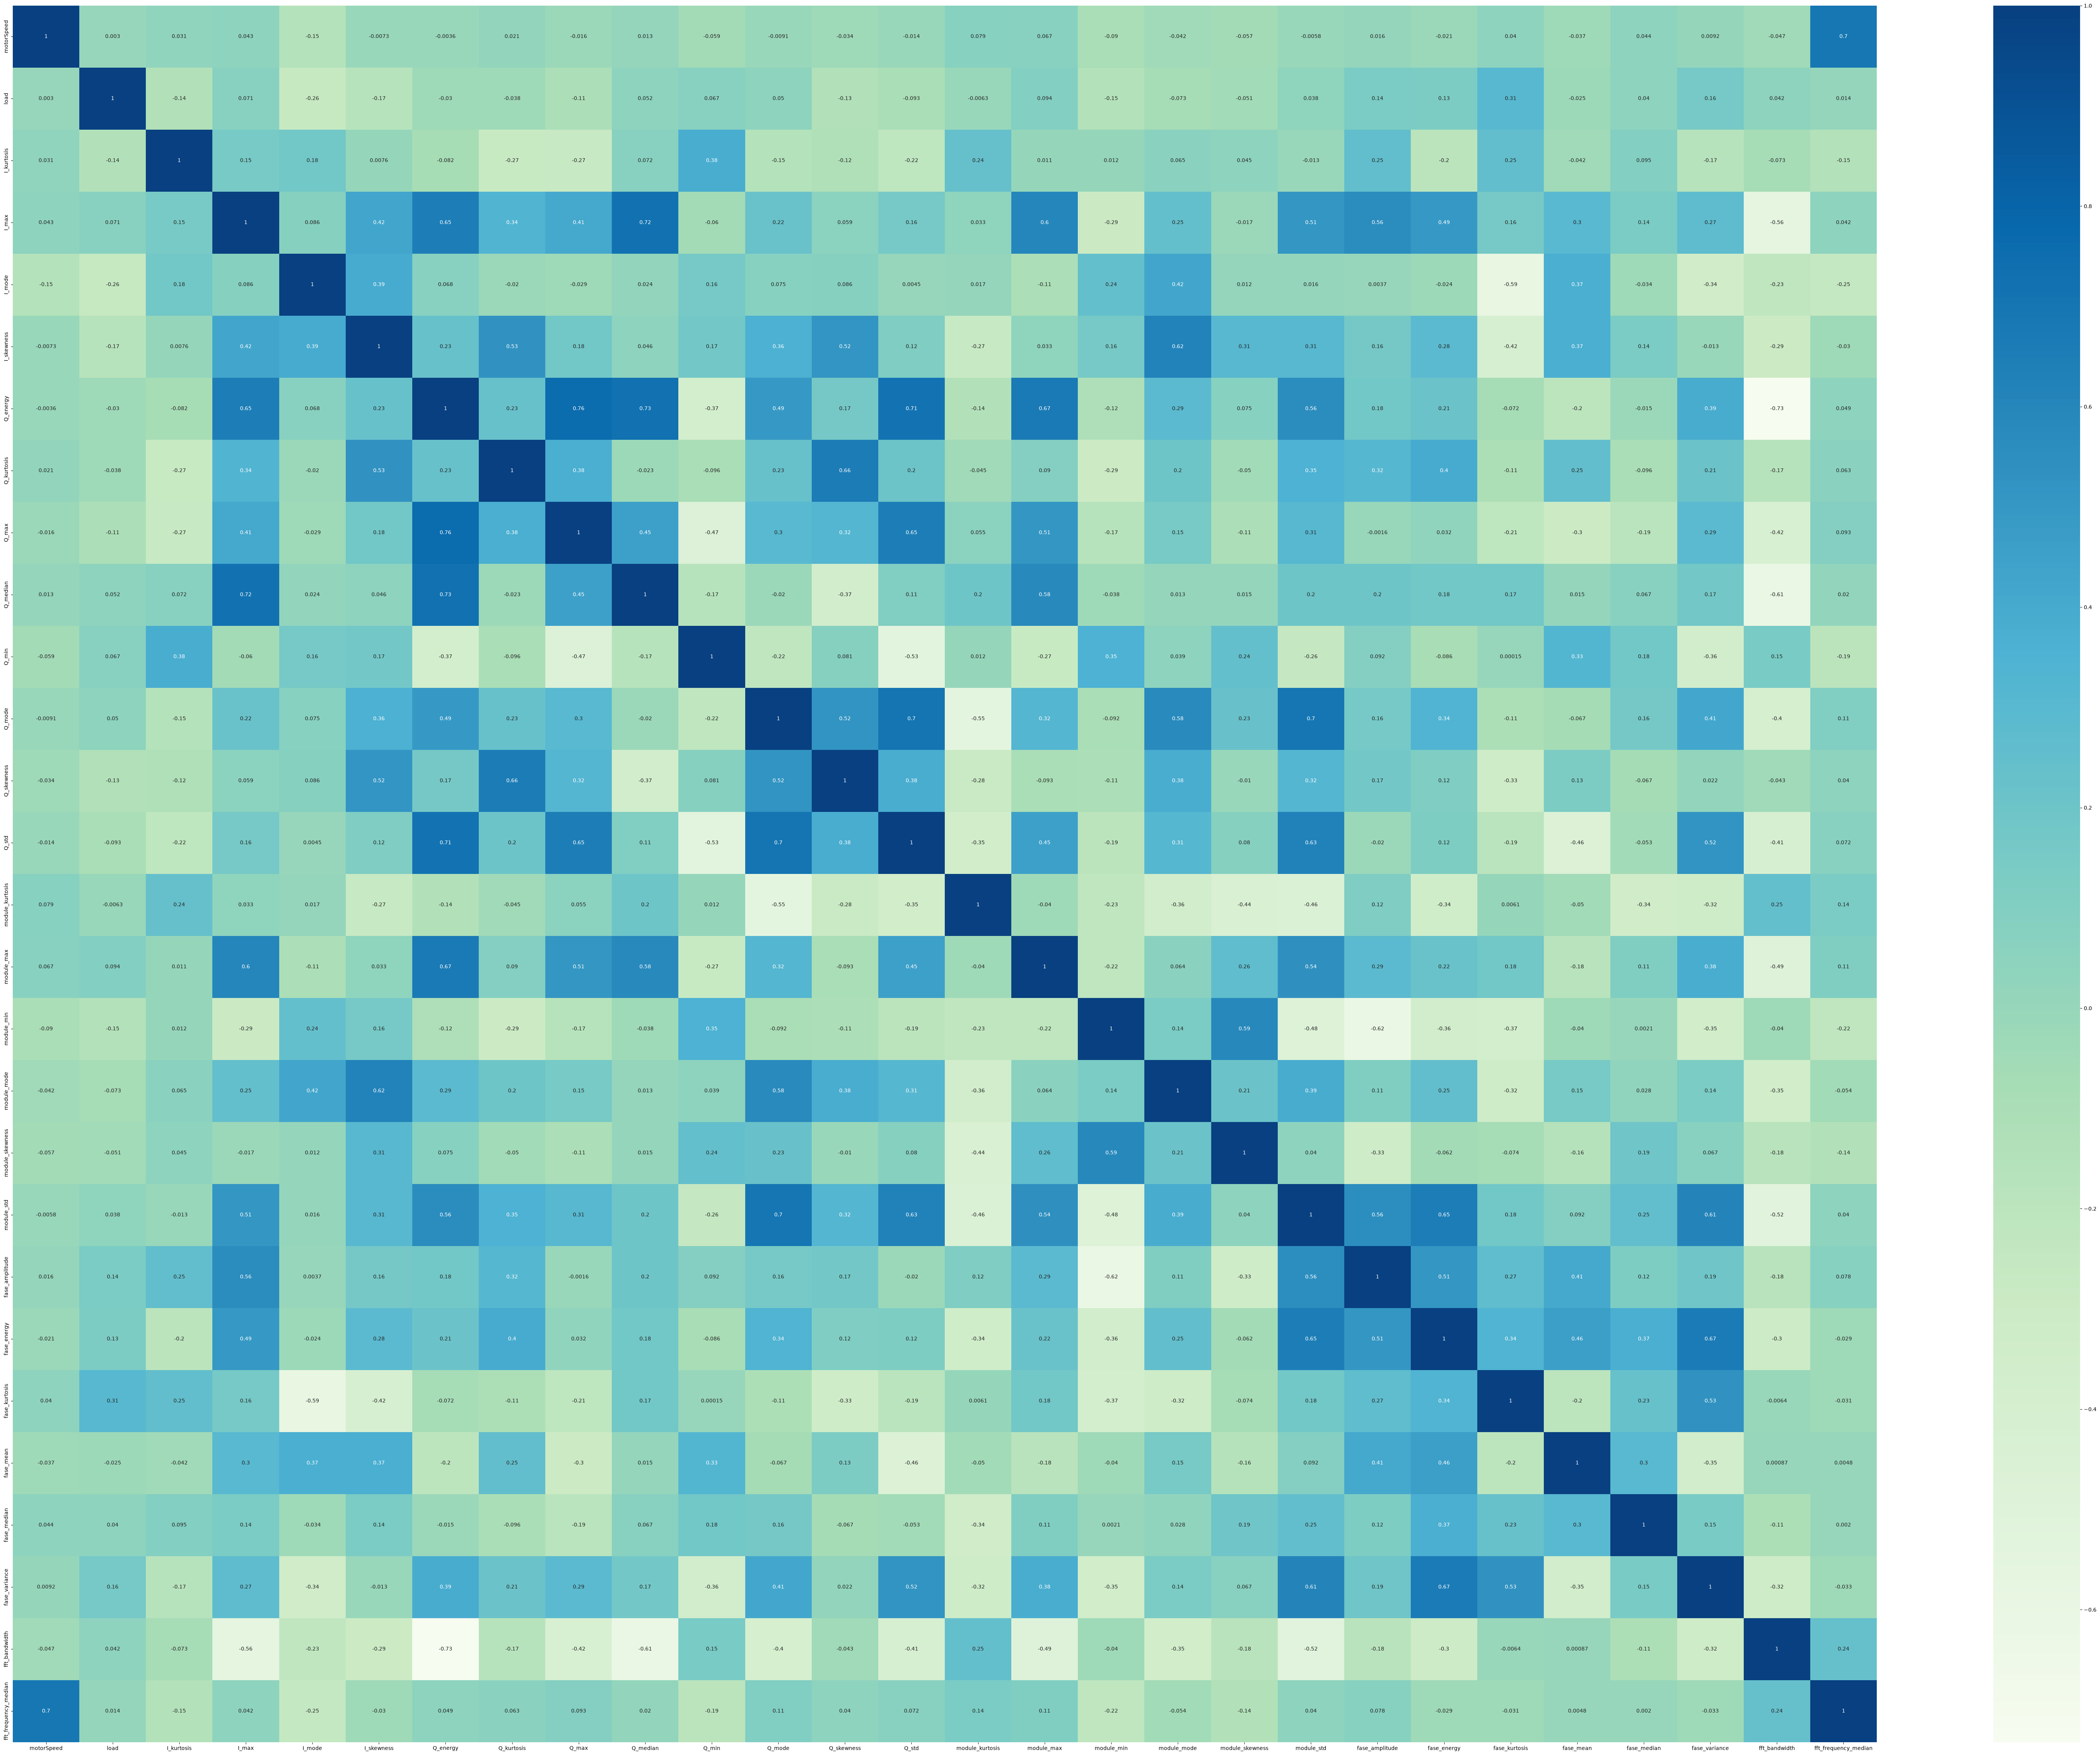

In [13]:
%matplotlib inline

max_high_correlation = 0
hate_high_correlation = 0.8

def count_high_correlation(data):
    mask = np.abs(data) >= hate_high_correlation
    return np.count_nonzero(mask)-1

def max_count_high_correlation(data):
    matriz_corr = data.corr()
    return np.max(matriz_corr.apply(count_high_correlation).sort_values(ascending=False))

def figure_corr(data):
    matriz_corr = data.corr()
    quantity_high_correlation = matriz_corr.apply(count_high_correlation).sort_values(ascending=False)
    plt.figure(figsize=(10, 6))
    plt.bar(quantity_high_correlation.index, quantity_high_correlation.values)
    plt.xticks(rotation=90)
    plt.ylabel("Quantidade de correlações")
    plt.xlabel("Feature")
    plt.tight_layout()
    plt.show()

def drop_high_correlation_feature(data):
    matriz_corr = data.corr()
    quantity_high_correlation = matriz_corr.apply(count_high_correlation).sort_values(ascending=False)
    feature_to_drop = quantity_high_correlation.index[0]
    return feature_to_drop, data.drop(columns=[feature_to_drop])


features_dropped = []

data_numeric_reduzido = data_numeric.copy()

# Retirando features com media e desvio padrão iguais a zero
mask = (data_numeric_reduzido.mean() == 0) & (data_numeric_reduzido.std() == 0)
features_removed = data_numeric_reduzido.columns[mask].tolist()
data_numeric_reduzido = data_numeric_reduzido.drop(columns=features_removed)
features_dropped.extend(features_removed)

# Retirando features com alta correlação
figure_corr(data_numeric_reduzido)

features_removed = []
while max_count_high_correlation(data_numeric_reduzido) > max_high_correlation:
    feature_dropped, data_numeric_reduzido = drop_high_correlation_feature(data_numeric_reduzido)
    features_removed.append(feature_dropped)

features_dropped.extend(features_removed)
print("Features removidas:\n" + '\n'.join(sorted(features_dropped)))

figure_corr(data_numeric_reduzido)
heatmap_corr(data_numeric_reduzido)


<h1>Criação de Pipelines </h1>

In [97]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

data_numeric = data_numeric_reduzido.select_dtypes(include="number")

scaler = MinMaxScaler()

pipeline_preprocessamento_class = LabelEncoder()
data_class = pipeline_preprocessamento_class.fit_transform(df_dataDetails['class'])


pipeline_preprocessamento_features = ColumnTransformer([
    ("scaler", StandardScaler(), data_numeric.select_dtypes("number").columns)
], remainder="drop")

pipeline_machineLearning = Pipeline([
    ("preprocessamento", pipeline_preprocessamento_features),
    ("modelo", GaussianNB())
])

param_grid = [
    {
        "modelo": [GaussianNB()]
    },
    {
        "modelo":[DecisionTreeClassifier(random_state=0)],
        "modelo__criterion": ['gini', 'entropy'],
        "modelo__max_depth": [3,6,9]
    },
    {
        "modelo":[RandomForestClassifier(random_state=0)],
        "modelo__n_estimators": [10, 20, 30],
        "modelo__max_depth": [3,6,9],
        "modelo__min_samples_split": [2, 5, 10],
        "modelo__min_samples_leaf": [1, 2, 4]
    }
]

grid_search = GridSearchCV(
    pipeline_machineLearning,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)


In [98]:
df_dataDetails["class"].unique()

<StringArray>
['Normal', 'Rotor', 'Bearing', 'Wound', 'Imbalance']
Length: 5, dtype: str

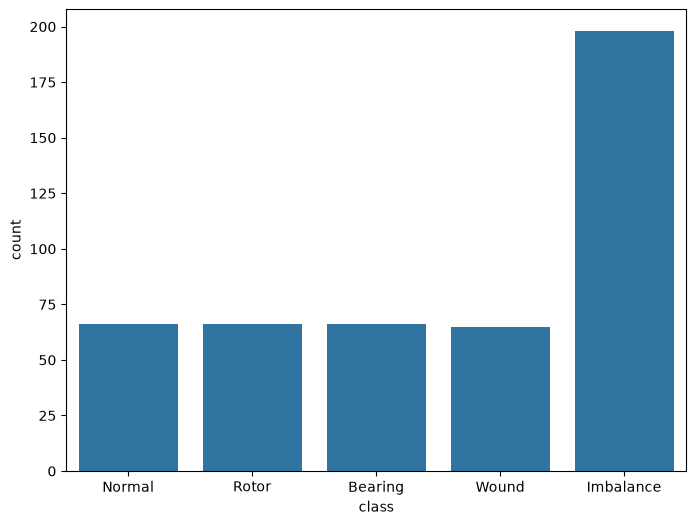

In [99]:
%matplotlib inline
plt.rcParams['figure.figsize'] = [8, 6]
sns.countplot(data=df_dataDetails, x="class")
plt.show()

In [100]:
X_train, X_test, y_train, y_test = train_test_split(data_numeric, data_class, test_size=0.7, random_state=0, stratify=data_class)
grid_search.fit(X_train, y_train)
print(grid_search.best_score_)
print(grid_search.best_params_)
print(grid_search.best_estimator_)
pd.DataFrame(grid_search.cv_results_)

0.9857142857142858
{'modelo': RandomForestClassifier(random_state=0), 'modelo__max_depth': 6, 'modelo__min_samples_leaf': 1, 'modelo__min_samples_split': 2, 'modelo__n_estimators': 10}
Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('scaler', StandardScaler(),
                                                  Index(['motorSpeed', 'load', 'I_kurtosis', 'I_max', 'I_mode', 'I_skewness',
       'Q_energy', 'Q_kurtosis', 'Q_max', 'Q_median', 'Q_min', 'Q_mode',
       'Q_skewness', 'Q_std', 'module_kurtosis', 'module_max', 'module_min',
       'module_mode', 'module_skewness', 'module_std', 'fase_amplitude',
       'fase_energy', 'fase_kurtosis', 'fase_mean', 'fase_median',
       'fase_variance', 'fft_bandwidth', 'fft_frequency_median'],
      dtype='str'))])),
                ('modelo',
                 RandomForestClassifier(max_depth=6, n_estimators=10,
                                        random_state=0))])


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_modelo,param_modelo__criterion,param_modelo__max_depth,param_modelo__min_samples_leaf,param_modelo__min_samples_split,param_modelo__n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.009112,0.000347,0.005166,0.000903,GaussianNB(),NaN,NaN,NaN,NaN,NaN,{'modelo': GaussianNB()},0.821429,0.928571,0.821429,0.925926,0.962963,0.892063,0.059135,88
1,0.008607,0.001734,0.004609,0.002149,DecisionTreeClassifier(random_state=0),gini,3.0,NaN,NaN,NaN,{'modelo': DecisionTreeClassifier(random_state...,0.928571,0.857143,0.892857,0.925926,0.962963,0.913492,0.035862,73
2,0.013296,0.000898,0.006239,0.001004,DecisionTreeClassifier(random_state=0),gini,6.0,NaN,NaN,NaN,{'modelo': DecisionTreeClassifier(random_state...,0.928571,0.892857,0.928571,0.925926,0.888889,0.912963,0.018106,74
3,0.009994,0.001665,0.006421,0.001208,DecisionTreeClassifier(random_state=0),gini,9.0,NaN,NaN,NaN,{'modelo': DecisionTreeClassifier(random_state...,0.928571,0.892857,0.928571,0.925926,0.888889,0.912963,0.018106,74
4,0.013023,0.002124,0.006632,0.000948,DecisionTreeClassifier(random_state=0),entropy,3.0,NaN,NaN,NaN,{'modelo': DecisionTreeClassifier(random_state...,0.928571,0.857143,0.892857,0.888889,0.962963,0.906085,0.036350,85
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,0.073722,0.003518,0.013026,0.002253,RandomForestClassifier(random_state=0),NaN,9.0,4.0,5.0,20.0,{'modelo': RandomForestClassifier(random_state...,0.964286,1.000000,0.928571,0.888889,0.962963,0.948942,0.037577,43
84,0.113602,0.020471,0.016835,0.003166,RandomForestClassifier(random_state=0),NaN,9.0,4.0,5.0,30.0,{'modelo': RandomForestClassifier(random_state...,0.964286,1.000000,0.964286,0.888889,1.000000,0.963492,0.040577,33
85,0.042669,0.001185,0.010545,0.001809,RandomForestClassifier(random_state=0),NaN,9.0,4.0,10.0,10.0,{'modelo': RandomForestClassifier(random_state...,0.964286,1.000000,0.892857,0.888889,0.925926,0.934392,0.042580,49
86,0.069734,0.005047,0.007743,0.002600,RandomForestClassifier(random_state=0),NaN,9.0,4.0,10.0,20.0,{'modelo': RandomForestClassifier(random_state...,0.964286,1.000000,0.928571,0.888889,0.962963,0.948942,0.037577,43


In [101]:
y_pred = grid_search.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.85      0.91        46
           1       0.88      0.99      0.94       139
           2       1.00      0.98      0.99        46
           3       1.00      0.78      0.88        46
           4       1.00      1.00      1.00        46

    accuracy                           0.94       323
   macro avg       0.97      0.92      0.94       323
weighted avg       0.95      0.94      0.94       323



In [102]:
model = grid_search.best_estimator_
x = df_dataDetails.drop(columns=['class'])
y = pipeline_preprocessamento_class.transform(df_dataDetails['class'])

y_pred = model.predict(x)
results = pd.DataFrame({"y Real": pipeline_preprocessamento_class.inverse_transform(y), "y Predi": pipeline_preprocessamento_class.inverse_transform(y_pred)})
results[results["y Real"] != results["y Predi"]]

,y Real,y Predi
44,Normal,Imbalance
115,Rotor,Imbalance
117,Rotor,Imbalance
118,Rotor,Imbalance
119,Rotor,Imbalance
120,Rotor,Imbalance
122,Rotor,Imbalance
123,Rotor,Imbalance
124,Rotor,Imbalance
129,Rotor,Imbalance
